In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rjmanoj/credit-card-customer-churn-prediction/Churn_Modelling.csv


> This notebook is for the learning purpose, its aim is to explore how Keras work, not to find good model

In [5]:
df = pd.read_csv('/kaggle/input/datasets/rjmanoj/credit-card-customer-churn-prediction/Churn_Modelling.csv')
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
df.shape

(10000, 14)

In [7]:
df.columns.to_list()

['RowNumber',
 'CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [9]:
df.select_dtypes(include = ['object', 'category']).columns.to_list()

['Surname', 'Geography', 'Gender']

In [10]:
df.select_dtypes(include = ['number']).columns.to_list()


['RowNumber',
 'CustomerId',
 'CreditScore',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [11]:
df.isnull().sum().sum()

np.int64(0)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
clean_df = df.drop(columns = ['RowNumber', 'Surname','CustomerId'])

In [14]:
clean_df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [15]:
clean_df.shape

(10000, 11)

In [16]:
clean_df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [17]:
clean_df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [18]:
clean_df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [19]:
import warnings
warnings.filterwarnings('ignore')

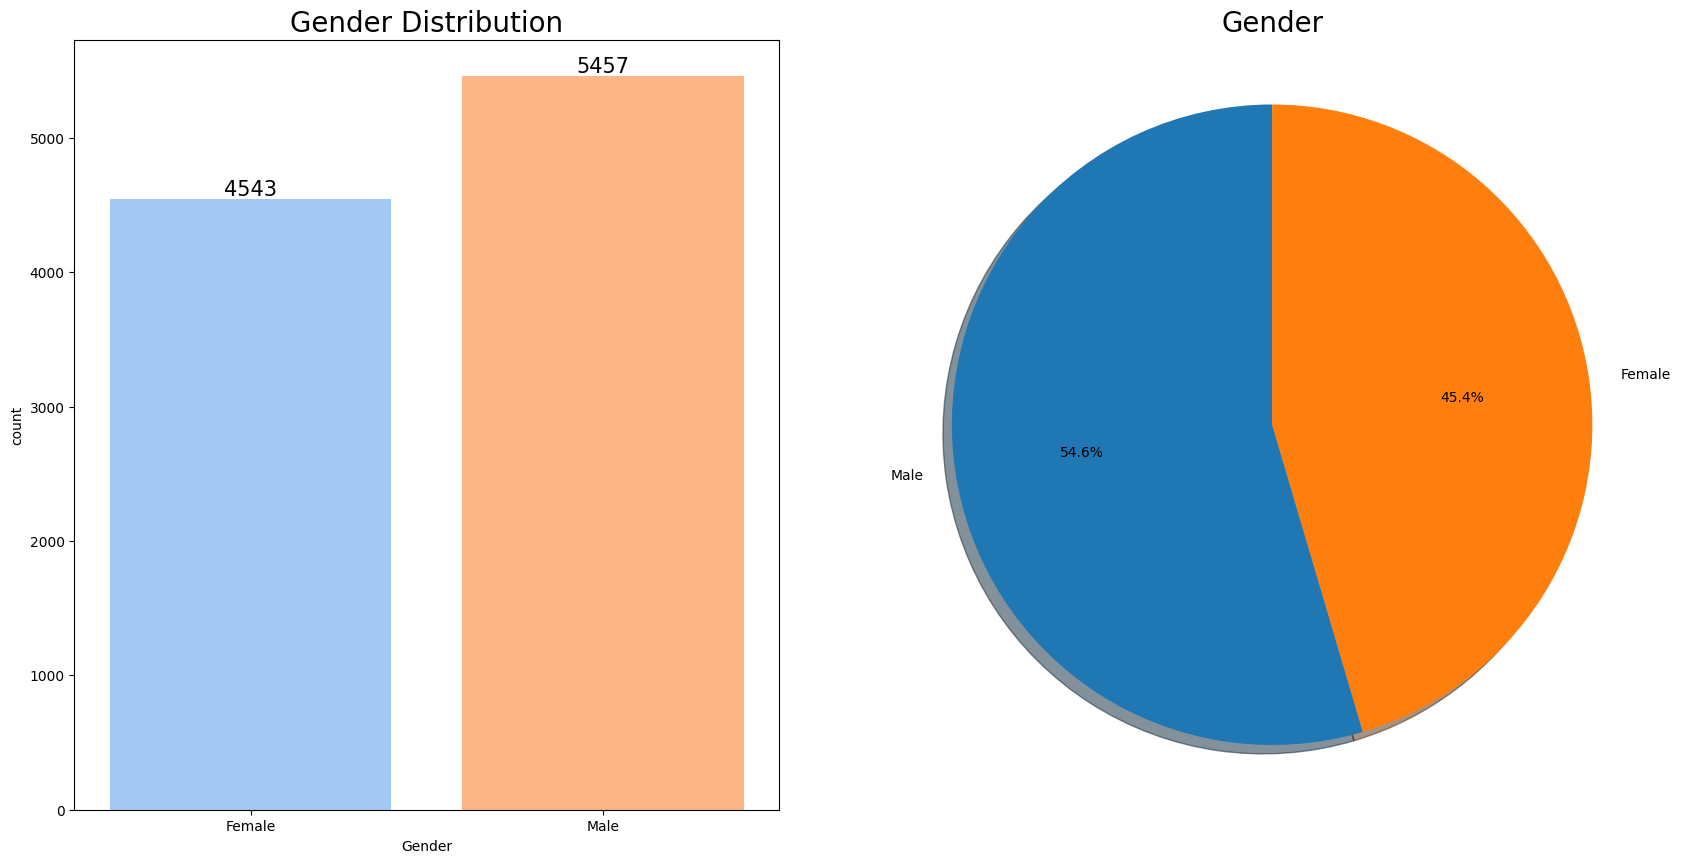

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns


fig, axs = plt.subplots(1, 2, figsize = (20, 10))

sns.countplot(clean_df, x = 'Gender', palette = 'pastel', saturation = 0.95, ax = axs[0])
axs[0].set_title('Gender Distribution', fontsize = 20)

for container in axs[0].containers:
    axs[0].bar_label(container, color = 'black', fontsize = 15)


axs[1].pie(clean_df['Gender'].value_counts(), labels = clean_df['Gender'].value_counts().index, autopct = '%1.1f%%', shadow = True, startangle = 90)
axs[1].axis('equal')
axs[1].set_title('Gender', fontsize = 20)

plt.show()

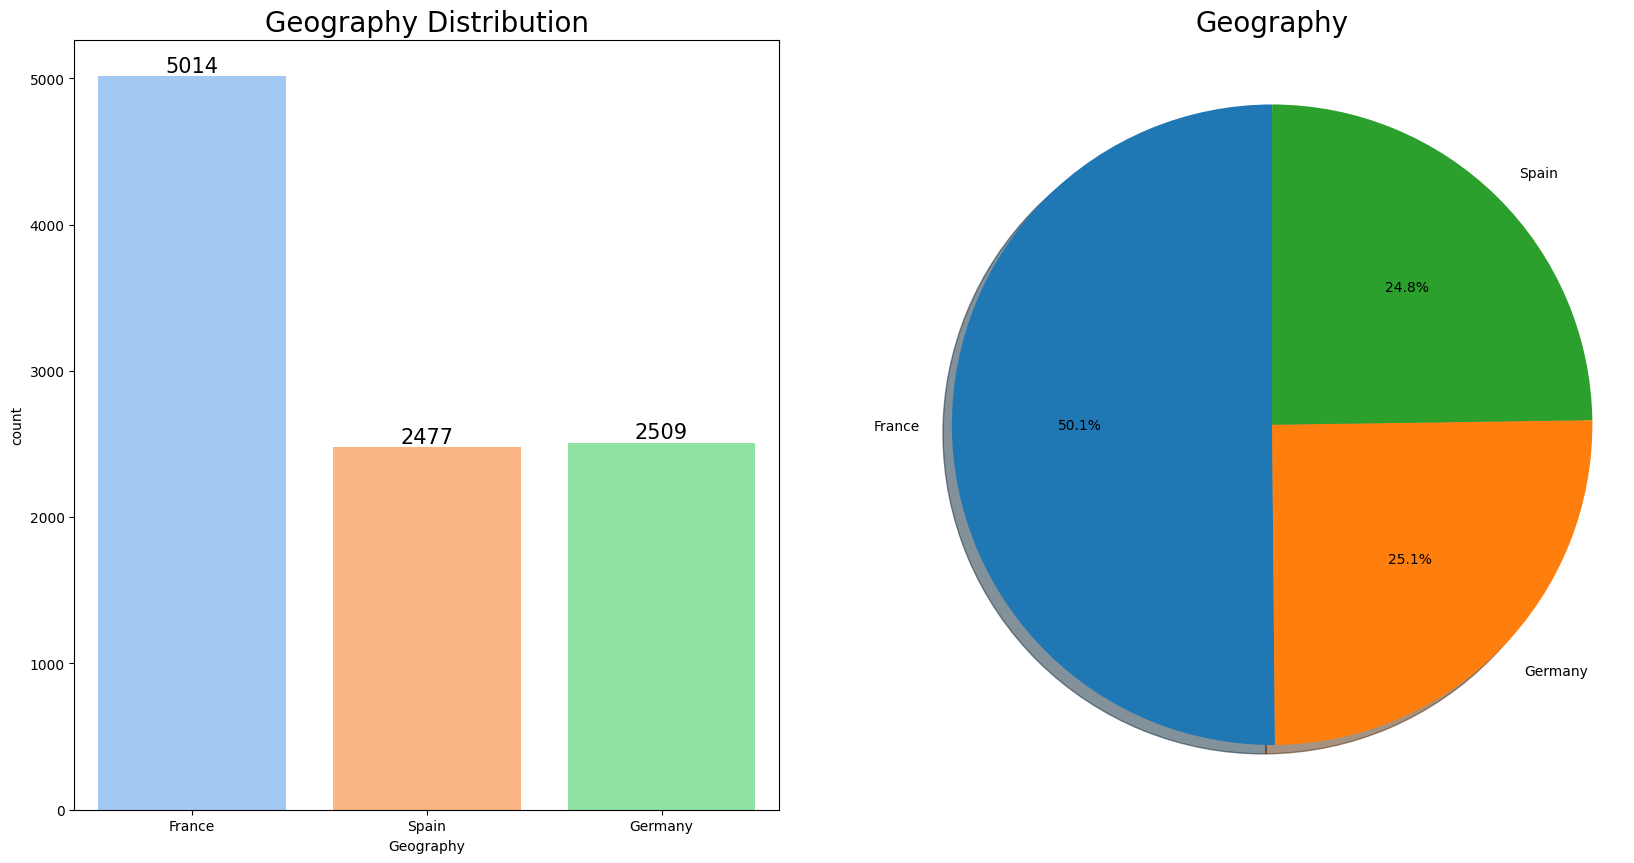

In [21]:
fig, axs = plt.subplots(1, 2, figsize = (20, 10))

sns.countplot(clean_df, x = 'Geography', palette = 'pastel', saturation = 0.95, ax = axs[0])
axs[0].set_title('Geography Distribution', fontsize = 20)

for container in axs[0].containers:
    axs[0].bar_label(container, color = 'black', fontsize = 15)


axs[1].pie(clean_df['Geography'].value_counts(), labels = clean_df['Geography'].value_counts().index, autopct = '%1.1f%%', shadow = True, startangle = 90)
axs[1].axis('equal')
axs[1].set_title('Geography', fontsize = 20)

plt.show()

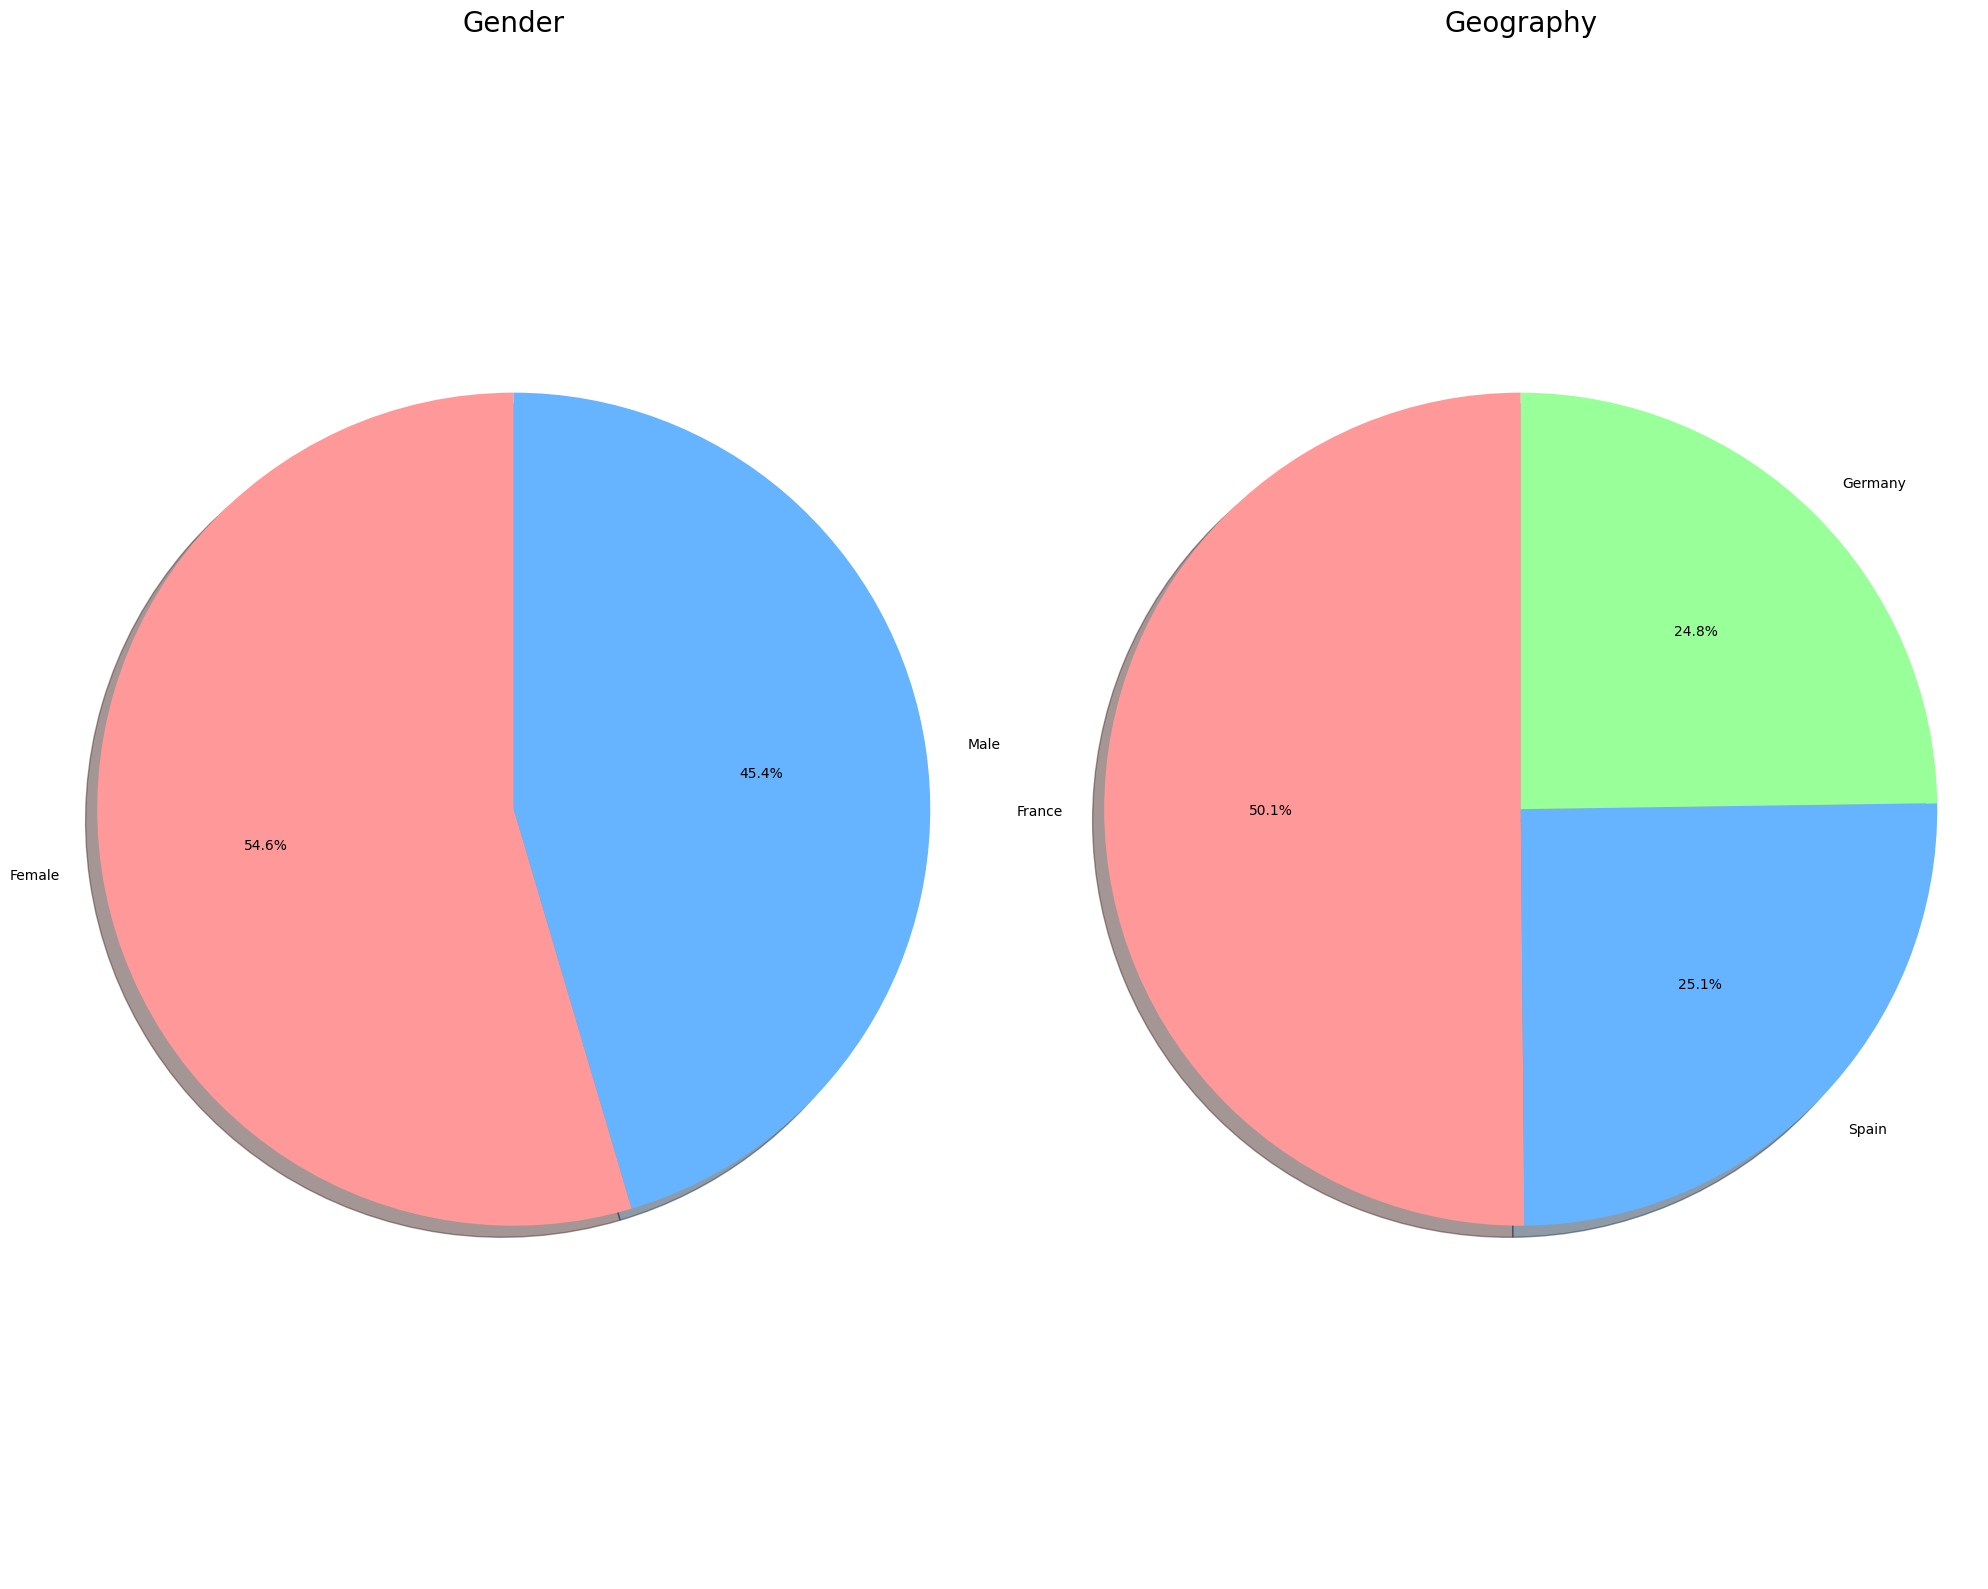

In [22]:
plt.rcParams['figure.figsize'] = (20, 16)

fig, axs = plt.subplots(1, 2)
size = clean_df['Gender'].value_counts()
labels = 'Female', 'Male'
colors = ['#ff9999','#66b3ff']

axs[0].pie(size, labels = labels, colors = colors, autopct = '%1.1f%%', shadow = True, startangle = 90)
axs[0].axis('equal')
axs[0].set_title('Gender', fontsize = 20)

size = clean_df['Geography'].value_counts()
labels = 'France', 'Spain', 'Germany'
colors = ['#ff9999','#66b3ff', '#99ff99']

axs[1].pie(size, labels = labels, colors = colors, autopct = '%1.1f%%', shadow = True, startangle = 90)
axs[1].axis('equal')
axs[1].set_title('Geography', fontsize = 20)



plt.tight_layout()
plt.show()
     

In [23]:
clean_df = pd.get_dummies(clean_df, columns=['Geography','Gender'],drop_first=True)

In [24]:
clean_df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [26]:
X = clean_df.drop(columns=['Exited'])
y = clean_df.Exited

In [27]:
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y,test_size=0.2,random_state=7)

In [28]:
Xtrain.shape, Xtest.shape, ytrain.shape, ytest.shape

((8000, 11), (2000, 11), (8000,), (2000,))

In [29]:
scaler = StandardScaler()
Xtrain_scaled = scaler.fit_transform(Xtrain)
Xtest_scaled = scaler.transform(Xtest)

In [30]:
Xtrain_scaled[:6]

array([[-0.22482832,  0.09984529,  1.37778936, -1.23433145, -0.90678651,
         0.64376017, -1.03667198, -1.73674714, -0.57581067, -0.57600312,
         0.91578261],
       [-0.8357854 , -0.84857831, -1.03726649,  0.87408518, -0.90678651,
         0.64376017,  0.96462528, -0.90580392, -0.57581067, -0.57600312,
         0.91578261],
       [-0.98075826,  0.66889946, -0.69225851,  0.8798357 , -0.90678651,
         0.64376017,  0.96462528,  0.14574389, -0.57581067,  1.73610172,
         0.91578261],
       [-0.27660434,  0.85858418, -0.69225851,  0.72938859,  0.80898739,
        -1.55337352, -1.03667198, -1.2172373 ,  1.73668197, -0.57600312,
        -1.09196221],
       [ 0.13760384,  0.19468766, -0.00224255, -1.23433145, -0.90678651,
         0.64376017,  0.96462528,  0.90214554, -0.57581067, -0.57600312,
        -1.09196221],
       [-1.32248001,  0.00500293, -1.38227446,  1.07459217, -0.90678651,
         0.64376017,  0.96462528,  0.32308108,  1.73668197, -0.57600312,
        -1.091

In [ ]:
# import tensorflow as tf
# print(tf.config.list_physical_devices('GPU'))

In [31]:
import keras
from keras import layers

Build The Model

In [53]:
model = keras.Sequential([
    keras.Input(shape = (11,)),

    layers.Dense(11, activation = 'relu'),
    layers.Dense(11, activation = 'relu'),
    layers.Dense(1, activation = 'sigmoid')
])

Configure The Model (Compile)

In [54]:
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

Model Summary

In [55]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

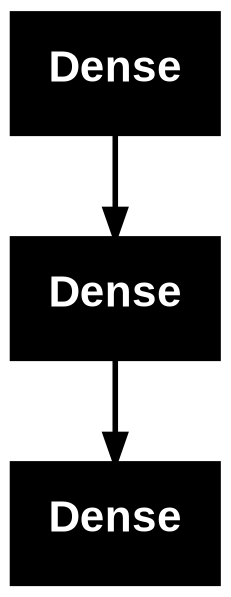

In [56]:
keras.utils.plot_model(model, "my_first_model.png")

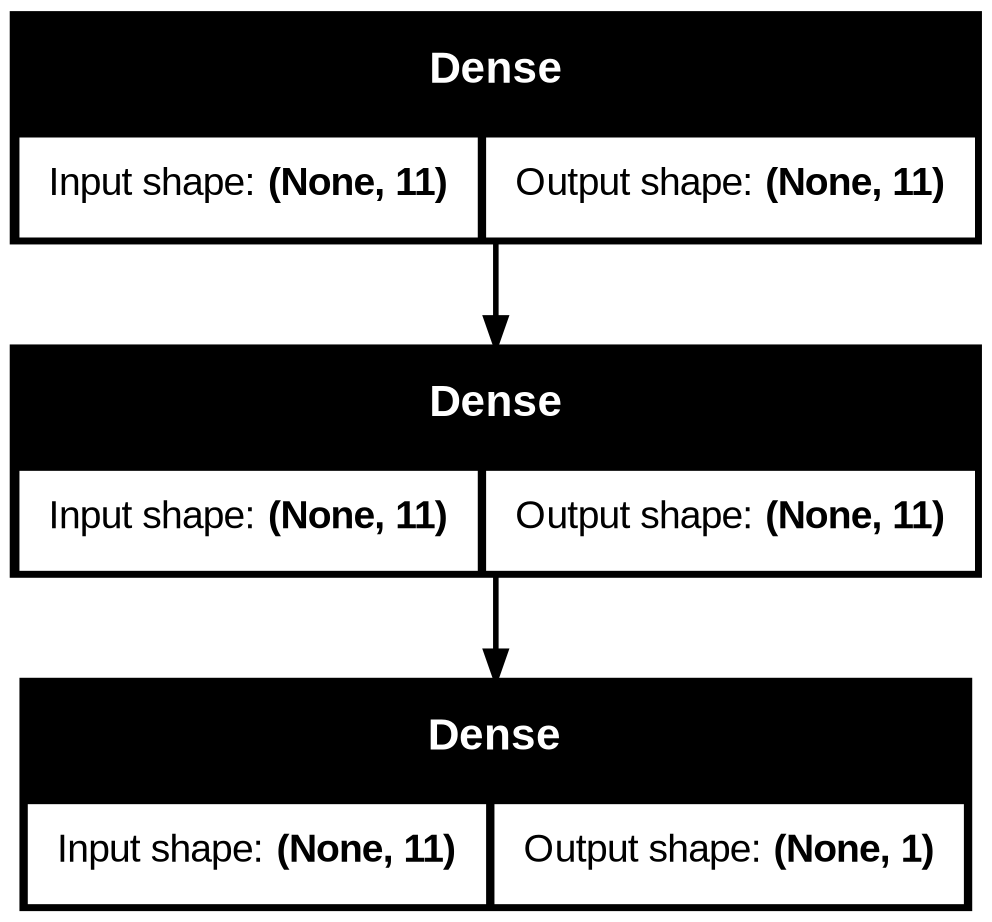

In [57]:
keras.utils.plot_model(model, "my_first_model_with_shape_info.png", show_shapes=True)

Fit The Model

In [58]:
history = model.fit(
    Xtrain_scaled,
    ytrain,
    validation_split = 0.2,
    epochs = 20,
    batch_size = 32
)

Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7939 - loss: 0.5249 - val_accuracy: 0.7944 - val_loss: 0.4977
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8086 - loss: 0.4499 - val_accuracy: 0.8050 - val_loss: 0.4607
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8198 - loss: 0.4187 - val_accuracy: 0.8150 - val_loss: 0.4396
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8297 - loss: 0.4010 - val_accuracy: 0.8244 - val_loss: 0.4224
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8363 - loss: 0.3867 - val_accuracy: 0.8288 - val_loss: 0.4097
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8430 - loss: 0.3754 - val_accuracy: 0.8331 - val_loss: 0.4004
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8486 - loss: 0.3663 - val_accuracy: 0.8363 - val_loss: 0.3887
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8527 - loss: 0.3595 - val_accuracy: 0.

Evaluate The Model

In [59]:
loss, accuracy = model.evaluate(Xtest_scaled, ytest)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8550 - loss: 0.3590
Test Loss: 0.35895323753356934
Test Accuracy: 0.8550000190734863


Make Predictions

In [60]:
predictions = model.predict(Xtest_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [61]:
predicted_calss = (predictions >= 0.5).astype(int)

In [62]:
model.layers[1].get_weights()

[array([[ 8.68089944e-02,  1.28572315e-01,  2.55562216e-01,
          4.59479958e-01,  4.07465361e-03,  3.60025913e-01,
         -2.69681364e-01, -3.80826354e-01,  8.19978118e-02,
          7.96638951e-02, -3.15547734e-01],
        [-3.57352227e-01,  1.90183863e-01, -5.26045918e-01,
          3.81269634e-01, -2.49127392e-02,  3.39568883e-01,
          2.45213017e-01,  6.04044497e-01, -1.55818179e-01,
          3.14694613e-01,  1.82579607e-02],
        [-4.39576805e-04,  7.45119631e-01, -4.93166119e-01,
         -4.83260870e-01,  1.84054393e-02,  6.64484799e-01,
         -1.85514629e-01, -6.45725787e-01, -3.61869395e-01,
         -3.74844193e-01,  1.25361681e-01],
        [-5.18844366e-01, -1.57924034e-02,  1.57686412e-01,
          5.06190777e-01, -1.05441004e-01, -1.59130752e-01,
         -2.61589199e-01, -4.10913378e-01, -4.98687699e-02,
          1.17713965e-01, -4.55052316e-01],
        [-9.76685360e-02,  6.23206973e-01, -9.84909683e-02,
         -1.24968521e-01, -4.13194090e-01,  

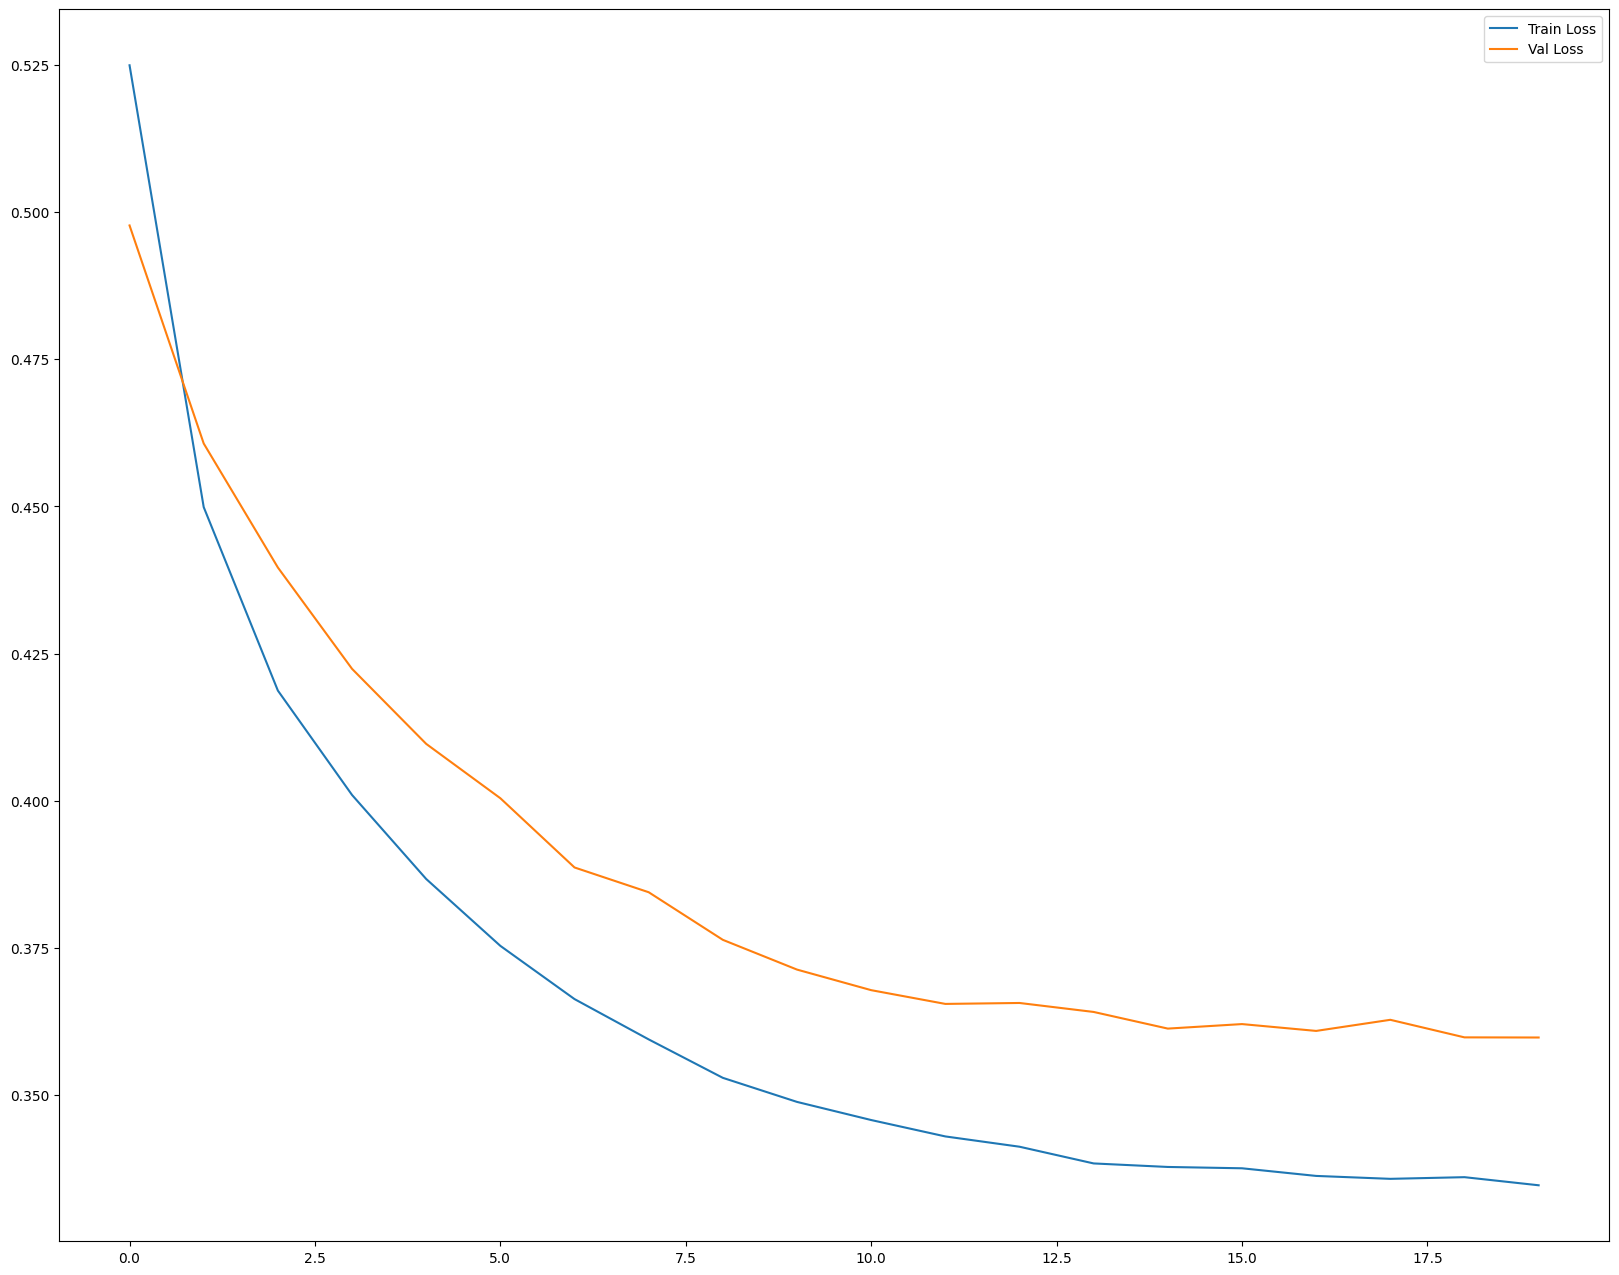

In [63]:
plt.plot(history.history['loss'], label = 'Train Loss')
plt.plot(history.history['val_loss'], label = 'Val Loss')
plt.legend()

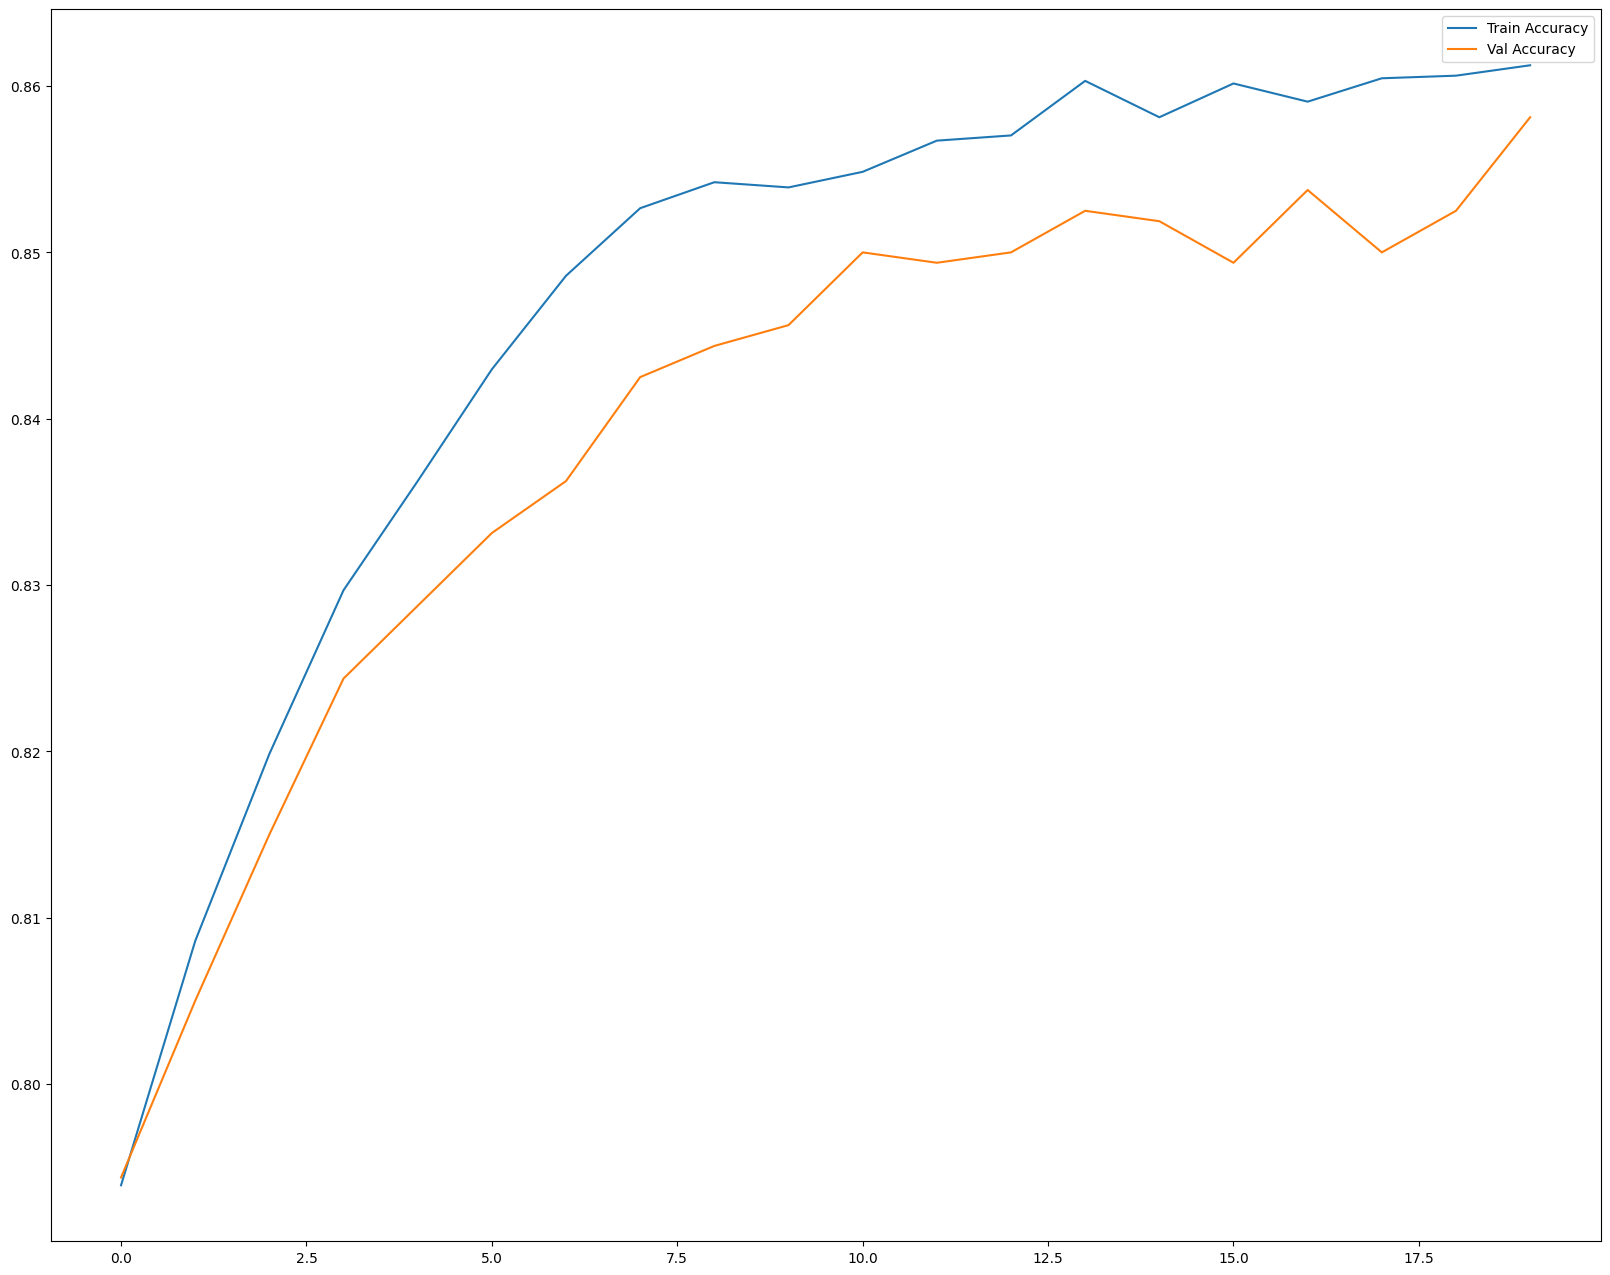

In [64]:
plt.plot(history.history['accuracy'], label = 'Train Accuracy')
plt.plot(history.history['val_accuracy'], label = 'Val Accuracy')
plt.legend()